In [2]:
import numpy as np

def linear_predict(X, b0, coefficients):
    X = np.asarray(X)
    coefficients = np.asarray(coefficients)
    return b0 + np.dot(X, coefficients)

house = [120, 3, 5]
b0 = 50
coefficients = [4.0, 20.0, -2.0]

prediction = linear_predict(house, b0, coefficients)
print('Manual prediction:', prediction)


Manual prediction: 580.0


In [3]:
def mse(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean((y_true - y_pred) ** 2)

y_true_demo = [100, 150, 200]
y_pred_demo = [110, 145, 190]
print('MSE:', mse(y_true_demo, y_pred_demo))


MSE: 75.0


In [4]:
X_demo = np.array([1, 2, 3, 4], dtype=float)
y_demo = np.array([3, 5, 7, 9], dtype=float)

b0 = 0.1
b1 = 0.1
learning_rate = 0.01
epochs = 100

mse_history = []

for epoch in range(epochs):
    # 1. Predict
    y_pred = b0 + b1 * X_demo

    # 2. Calculate error and MSE
    error = y_pred - y_demo
    current_mse = np.mean(error ** 2)
    mse_history.append(current_mse)

    # 3. Calculate gradients
    db0 = 2 * np.mean(error)
    db1 = 2 * np.mean(error * X_demo)

    # 4. Update parameters
    b0 = b0 - learning_rate * db0
    b1 = b1 - learning_rate * db1

print('Learned b0:', b0)
print('Learned b1:', b1)
print('Final MSE:', mse_history[-1])


Learned b0: 0.8314696852380623
Learned b1: 2.0573208331577493
Final MSE: 0.004772092662999359


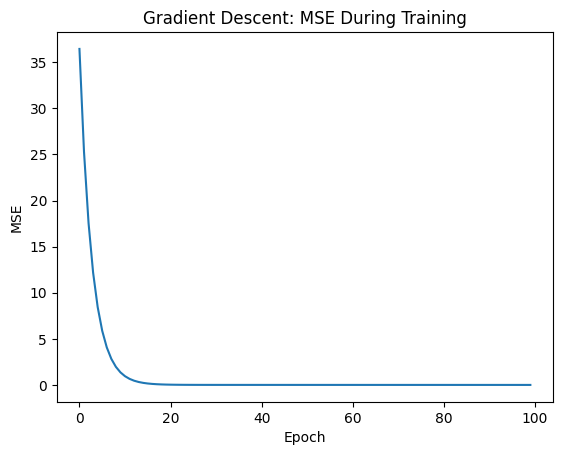

In [5]:
import matplotlib.pyplot as plt

plt.plot(mse_history)
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Gradient Descent: MSE During Training')
plt.show()


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()
print('Dataset loaded successfully.')
display(df.head())


Dataset loaded successfully.


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [7]:
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
df.info()
display(df.describe().T)
print('Missing values:')
print(df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())


Shape: (20640, 9)
Columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64
Duplicate rows: 0


In [8]:
before = len(df)
df = df.drop_duplicates().copy()
print('Duplicates removed:', before - len(df))

valid_mask = (
    (df['HouseAge'] >= 0) &
    (df['AveRooms'] > 0) &
    (df['AveOccup'] > 0)
)
df = df.loc[valid_mask].copy()
print('Shape after validity checks:', df.shape)


Duplicates removed: 0
Shape after validity checks: (20640, 9)


In [9]:
numeric_columns = df.select_dtypes(include=np.number).columns
for col in numeric_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

print(df.isnull().sum())


MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


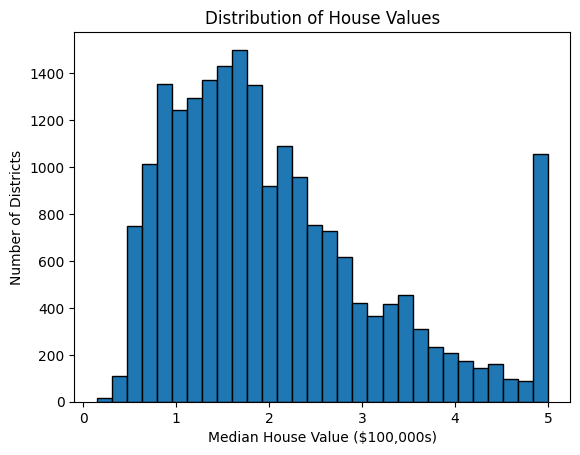

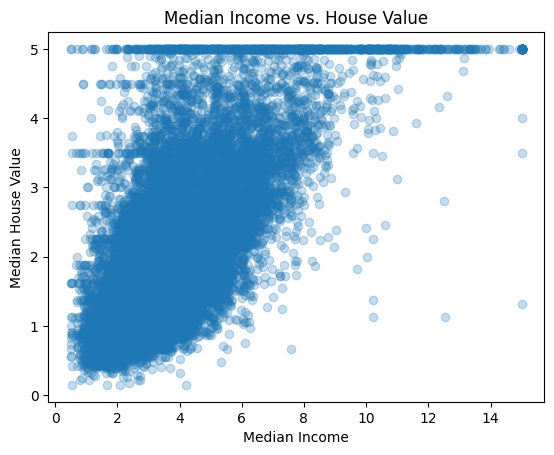

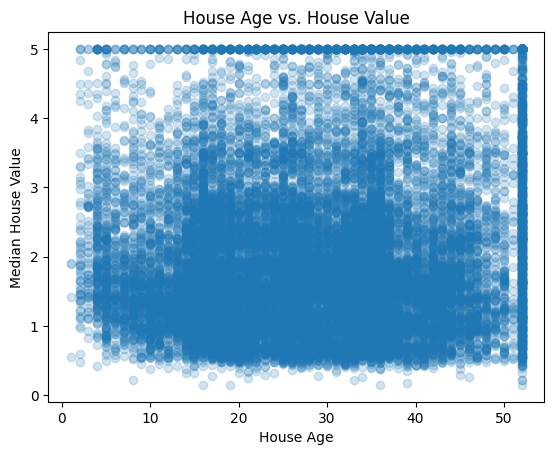

In [10]:
plt.hist(df['MedHouseVal'], bins=30, edgecolor='black')
plt.xlabel('Median House Value ($100,000s)')
plt.ylabel('Number of Districts')
plt.title('Distribution of House Values')
plt.show()

plt.scatter(df['MedInc'], df['MedHouseVal'], alpha=0.25)
plt.xlabel('Median Income')
plt.ylabel('Median House Value')
plt.title('Median Income vs. House Value')
plt.show()

plt.scatter(df['HouseAge'], df['MedHouseVal'], alpha=0.20)
plt.xlabel('House Age')
plt.ylabel('Median House Value')
plt.title('House Age vs. House Value')
plt.show()


In [11]:
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']
print('X shape:', X.shape)
print('y shape:', y.shape)
display(X.head())


X shape: (20640, 8)
y shape: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))


Training rows: 16512
Testing rows: 4128


In [13]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

print('Intercept b0:', linear_model.intercept_)
coef_table = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': linear_model.coef_
})
display(coef_table)


Intercept b0: -37.02327770606409


,Feature,Coefficient
0,MedInc,0.448675
1,HouseAge,0.009724
2,AveRooms,-0.123323
3,AveBedrms,0.783145
4,Population,-0.000002
5,AveOccup,-0.003526
6,Latitude,-0.419792
7,Longitude,-0.433708


In [14]:
first_house = X_test.iloc[0].values

manual_prediction = linear_predict(
    first_house,
    linear_model.intercept_,
    linear_model.coef_
)
sklearn_prediction = linear_model.predict(X_test.iloc[[0]])[0]

print('Manual prediction:', manual_prediction)
print('scikit-learn prediction:', sklearn_prediction)
print('Difference:', abs(manual_prediction - sklearn_prediction))


Manual prediction: 0.7191228416019086
scikit-learn prediction: 0.7191228416019086
Difference: 0.0


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_linear = linear_model.predict(X_test)
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = mean_squared_error(y_test, y_pred_linear) ** 0.5
r2_linear = r2_score(y_test, y_pred_linear)

print(f'MAE: {mae_linear:.4f}')
print(f'RMSE: {rmse_linear:.4f}')
print(f'R²: {r2_linear:.4f}')


MAE: 0.5332
RMSE: 0.7456
R²: 0.5758


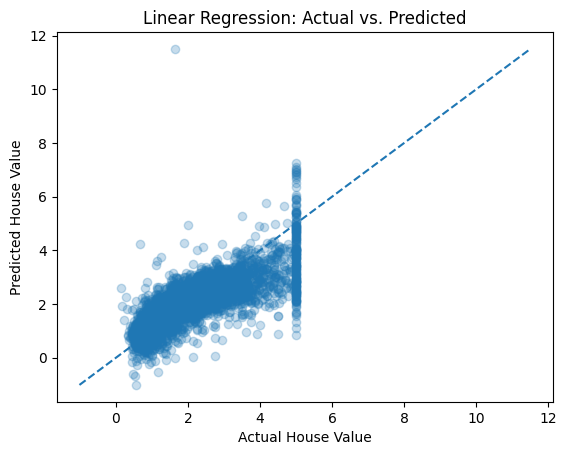

In [16]:
plt.scatter(y_test, y_pred_linear, alpha=0.25)
plt.xlabel('Actual House Value')
plt.ylabel('Predicted House Value')
plt.title('Linear Regression: Actual vs. Predicted')
min_val = min(y_test.min(), y_pred_linear.min())
max_val = max(y_test.max(), y_pred_linear.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle='--')
plt.show()


In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])


In [18]:
from sklearn.model_selection import GridSearchCV
param_grid = {'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 100]}

grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error'
)
grid.fit(X_train, y_train)

print('Best alpha:', grid.best_params_['ridge__alpha'])
print('Best cross-validation score:', grid.best_score_)


Best alpha: 0.001
Best cross-validation score: -0.5192652014850863


,alpha,CV_RMSE
0,0.001,0.720601
1,0.010,0.720601
2,0.100,0.720601
3,1.000,0.720601
4,10.000,0.720613
5,100.000,0.721445


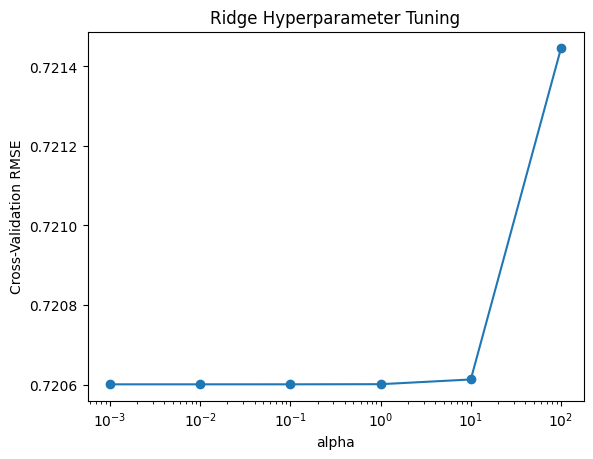

In [19]:
cv_results = pd.DataFrame(grid.cv_results_)
alpha_results = cv_results[['param_ridge__alpha', 'mean_test_score']].copy()
alpha_results['CV_RMSE'] = np.sqrt(-alpha_results['mean_test_score'])
alpha_results = alpha_results.rename(columns={'param_ridge__alpha': 'alpha'})
display(alpha_results[['alpha', 'CV_RMSE']])

plt.plot(alpha_results['alpha'].astype(float), alpha_results['CV_RMSE'], marker='o')
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Cross-Validation RMSE')
plt.title('Ridge Hyperparameter Tuning')
plt.show()


In [20]:
best_ridge = grid.best_estimator_
y_pred_ridge = best_ridge.predict(X_test)

mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
rmse_ridge = mean_squared_error(y_test, y_pred_ridge) ** 0.5
r2_ridge = r2_score(y_test, y_pred_ridge)

comparison = pd.DataFrame({
    'Model': ['Linear Regression', f"Ridge (alpha={grid.best_params_['ridge__alpha']})"],
    'MAE': [mae_linear, mae_ridge],
    'RMSE': [rmse_linear, rmse_ridge],
    'R2': [r2_linear, r2_ridge]
})
display(comparison.round(4))


,Model,MAE,RMSE,R2
0,Linear Regression,0.5332,0.7456,0.5758
1,Ridge (alpha=0.001),0.5332,0.7456,0.5758


In [21]:
new_house = pd.DataFrame([{
    'MedInc': 5.0, 'HouseAge': 25.0, 'AveRooms': 5.5,
    'AveBedrms': 1.1, 'Population': 1200.0, 'AveOccup': 3.0,
    'Latitude': 34.05, 'Longitude': -118.25
}])
new_house = new_house[X.columns]

new_prediction = best_ridge.predict(new_house)[0]
print(f'Predicted median house value: {new_prediction:.3f} × $100,000')
print(f'Approximate dollar value: ${new_prediction * 100000:,.0f}')


Predicted median house value: 2.625 × $100,000
Approximate dollar value: $262,541
